In [1]:
# 1. Pipeline Environment & Dataset Verification
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import json
import qiskit
import sklearn

# Set paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_and_verify_workbook, EXPECTED_FEATURE_COLUMNS

print(f'Python: {sys.version}')
print(f'Qiskit: {qiskit.__version__}')
print(f'Scikit-learn: {sklearn.__version__}')

dataset = load_and_verify_workbook()
print(f'Stage1_Train shape: {dataset.stage1_train.shape} (strictly 300 rows)')
print(f'Stage1_Test shape: {dataset.stage1_test.shape} (strictly 100 rows)')
print(f'Positive conversion rate on train: {np.mean(dataset.stage1_train["y"] == "yes") * 100:.2f}%')


Python: 3.13.13 | packaged by conda-forge | (main, Apr  8 2026, 02:29:07) [Clang 19.1.7 ]
Qiskit: 2.6.2
Scikit-learn: 1.9.1
Stage1_Train shape: (300, 17) (strictly 300 rows)
Stage1_Test shape: (100, 16) (strictly 100 rows)
Positive conversion rate on train: 11.67%


In [2]:
# 2. Stage 1: Subscription Probability Prediction (5-Fold CV & Inference)
from src.stage1_predict import validate_stage1_only, rank_stage1_predictions, EndToEndQuantumClassifier

summary = validate_stage1_only(dataset.stage1_train, seed=42)
print(f'Selected Production Model: {summary.selected_model_name}')

metrics_df = pd.DataFrame([
    {
        'Model': m,
        'ROC-AUC': mets['pooled_oof']['roc_auc'],
        'PR-AUC (AP)': mets['pooled_oof']['pr_auc_average_precision'],
        'Brier Score': mets['pooled_oof']['brier_score'],
        'Log-Loss': mets['pooled_oof']['log_loss'],
        '5-Bin ECE': mets['pooled_oof']['ece_5bin'],
        'S_train': mets['composite_train_score'],
    }
    for m, mets in summary.cv_metrics_by_model.items()
])
display(metrics_df)

# Load official stage 1 results
stage1_res = pd.read_csv(PROJECT_ROOT / 'stage1_results.csv')
print('\nTop 10 Ranked Customers for Stage 2 Optimization:')
display(stage1_res.head(10))


Selected Production Model: Hybrid-Quantum-FeatureAug-LogReg


,Model,ROC-AUC,PR-AUC (AP),Brier Score,Log-Loss,5-Bin ECE,S_train
0,Hybrid-Quantum-FeatureAug-LogReg,0.675040,0.226505,0.100065,0.34293,0.015231,0.284507
1,Classical-LogisticRegression-L2,0.624798,0.199869,0.101945,0.35370,0.007163,0.243243



Top 10 Ranked Customers for Stage 2 Optimization:


,customer_id,predicted_probability,rank,top_10_flag
0,C0031,0.297988,1,1
1,C0170,0.247652,2,1
2,C0079,0.240192,3,1
3,C0081,0.233244,4,1
4,C0193,0.232499,5,1
5,C0265,0.214620,6,1
6,C0188,0.210171,7,1
7,C0183,0.199532,8,1
8,C0318,0.197925,9,1
9,C0256,0.194275,10,1


In [3]:
# 3. Stage 2: Constrained Resource Optimization (Dicke XY-QAOA)
with open(PROJECT_ROOT / 'stage2_results.json') as f:
    s2 = json.load(f)

print('=== Stage 2 Quantum Optimization Results ===')
print(f'Selected Customers: {s2["quantum_solution"]["selected_customer_ids"]}')
print(f'Selected Bitstring: {s2["quantum_solution"]["selected_bitstring_little_endian"]}')
print(f'Expected Net Value: {s2["quantum_solution"]["objective_expected_net_value"]:.6f}')
print(f'Total Contact Cost: {s2["quantum_solution"]["total_contact_cost"]} (Budget <= 25.0)')
print(f'Total Capacity: {s2["quantum_solution"]["total_capacity_units"]} (Capacity <= 22.0)')
print(f'Optimality Gap vs Classical Exact 210: {s2["comparison"]["absolute_optimality_gap"]:.6f}')

# Business Comparison vs Naive Top-6
print('\n=== Business ROI vs. Naive Top-6 CRM Strategy ===')
top10_df = pd.DataFrame(s2['top_10_candidates'])
naive_net = top10_df.iloc[:6]['expected_net_value'].sum()
opt_net = s2['quantum_solution']['objective_expected_net_value']
gain_pct = (opt_net - naive_net) / naive_net * 100

print(f'Naive Top-6 Expected Net Profit: {naive_net:.4f}')
print(f'Stage 2 QAOA Expected Net Profit: {opt_net:.4f}')
print(f'Net Profit Advantage: +{gain_pct:.1f}% higher expected return!')

print('\nResource Optimization Summary:')
res = s2['circuit_resources']
print(f'Transpiled CX gates: {res["transpiled_1q2q_gate_counts"]["cx"]} (slashed from 4,379: -90.27%)')
print(f'Transpiled Depth: {res["transpiled_1q2q_depth"]} (slashed from 11,199: -93.38%)')
print(f'Dicke State Preparation CX: {res["dicke_state_preparation_overhead_included"]["bartschi_eidenbenz_scs_transpiled_cx"]}')


=== Stage 2 Quantum Optimization Results ===
Selected Customers: ['C0031', 'C0170', 'C0079', 'C0265', 'C0318', 'C0256']
Selected Bitstring: 1100100111
Expected Net Value: 14.453526
Total Contact Cost: 14.0 (Budget <= 25.0)
Total Capacity: 16.0 (Capacity <= 22.0)
Optimality Gap vs Classical Exact 210: 0.000000

=== Business ROI vs. Naive Top-6 CRM Strategy ===
Naive Top-6 Expected Net Profit: 10.7082
Stage 2 QAOA Expected Net Profit: 14.4535
Net Profit Advantage: +35.0% higher expected return!

Resource Optimization Summary:
Transpiled CX gates: 426 (slashed from 4,379: -90.27%)
Transpiled Depth: 741 (slashed from 11,199: -93.38%)
Dicke State Preparation CX: 246


In [4]:
# 4. Stage 3: Campaign Conversion Simulation & Risk Analysis
with open(PROJECT_ROOT / 'stage3_results.json') as f:
    s3 = json.load(f)

print('=== Probability of At Least 3 Conversions P(S >= 3) ===')
for method, val in s3['summary_estimates_prob_at_least_3'].items():
    print(f'  {method:<40}: {val:.6f}')

print('\nAnalytical Sensitivity Derivatives dP/dp_i = P(S_{-i} = 2):')
sens_dict = s3['analytical_sensitivity_derivatives']['analytical_gradient_wrt_p']
sens_df = pd.DataFrame([
    {
        'Qubit': item['qubit_index'],
        'Customer ID': item['customer_id'],
        'Predicted Prob p_i': item['predicted_probability'],
        'Sensitivity dP/dp_i': sens_dict[item['customer_id']],
    }
    for item in s3['qubit_to_customer_mapping']
])
display(sens_df)


=== Probability of At Least 3 Conversions P(S >= 3) ===
  exact_poisson_binomial_dp               : 0.141288
  exact_64_outcome_enumeration            : 0.141288
  ideal_quantum_statevector               : 0.141288
  noiseless_quantum_shots_100k            : 0.140470
  classical_monte_carlo_100k              : 0.141020
  noisy_gate_depolarizing_only_100k       : 0.148630
  noisy_readout_error_only_100k           : 0.153690
  noisy_combined_depol_and_readout_100k   : 0.164470

Analytical Sensitivity Derivatives dP/dp_i = P(S_{-i} = 2):


,Qubit,Customer ID,Predicted Prob p_i,Sensitivity dP/dp_i
0,0,C0031,0.297988,0.228643
1,1,C0170,0.247652,0.241141
2,2,C0079,0.240192,0.242921
3,3,C0265,0.214620,0.248809
4,4,C0318,0.197925,0.252453
5,5,C0256,0.194275,0.253227


Displaying: stage1_validation_and_calibration.png


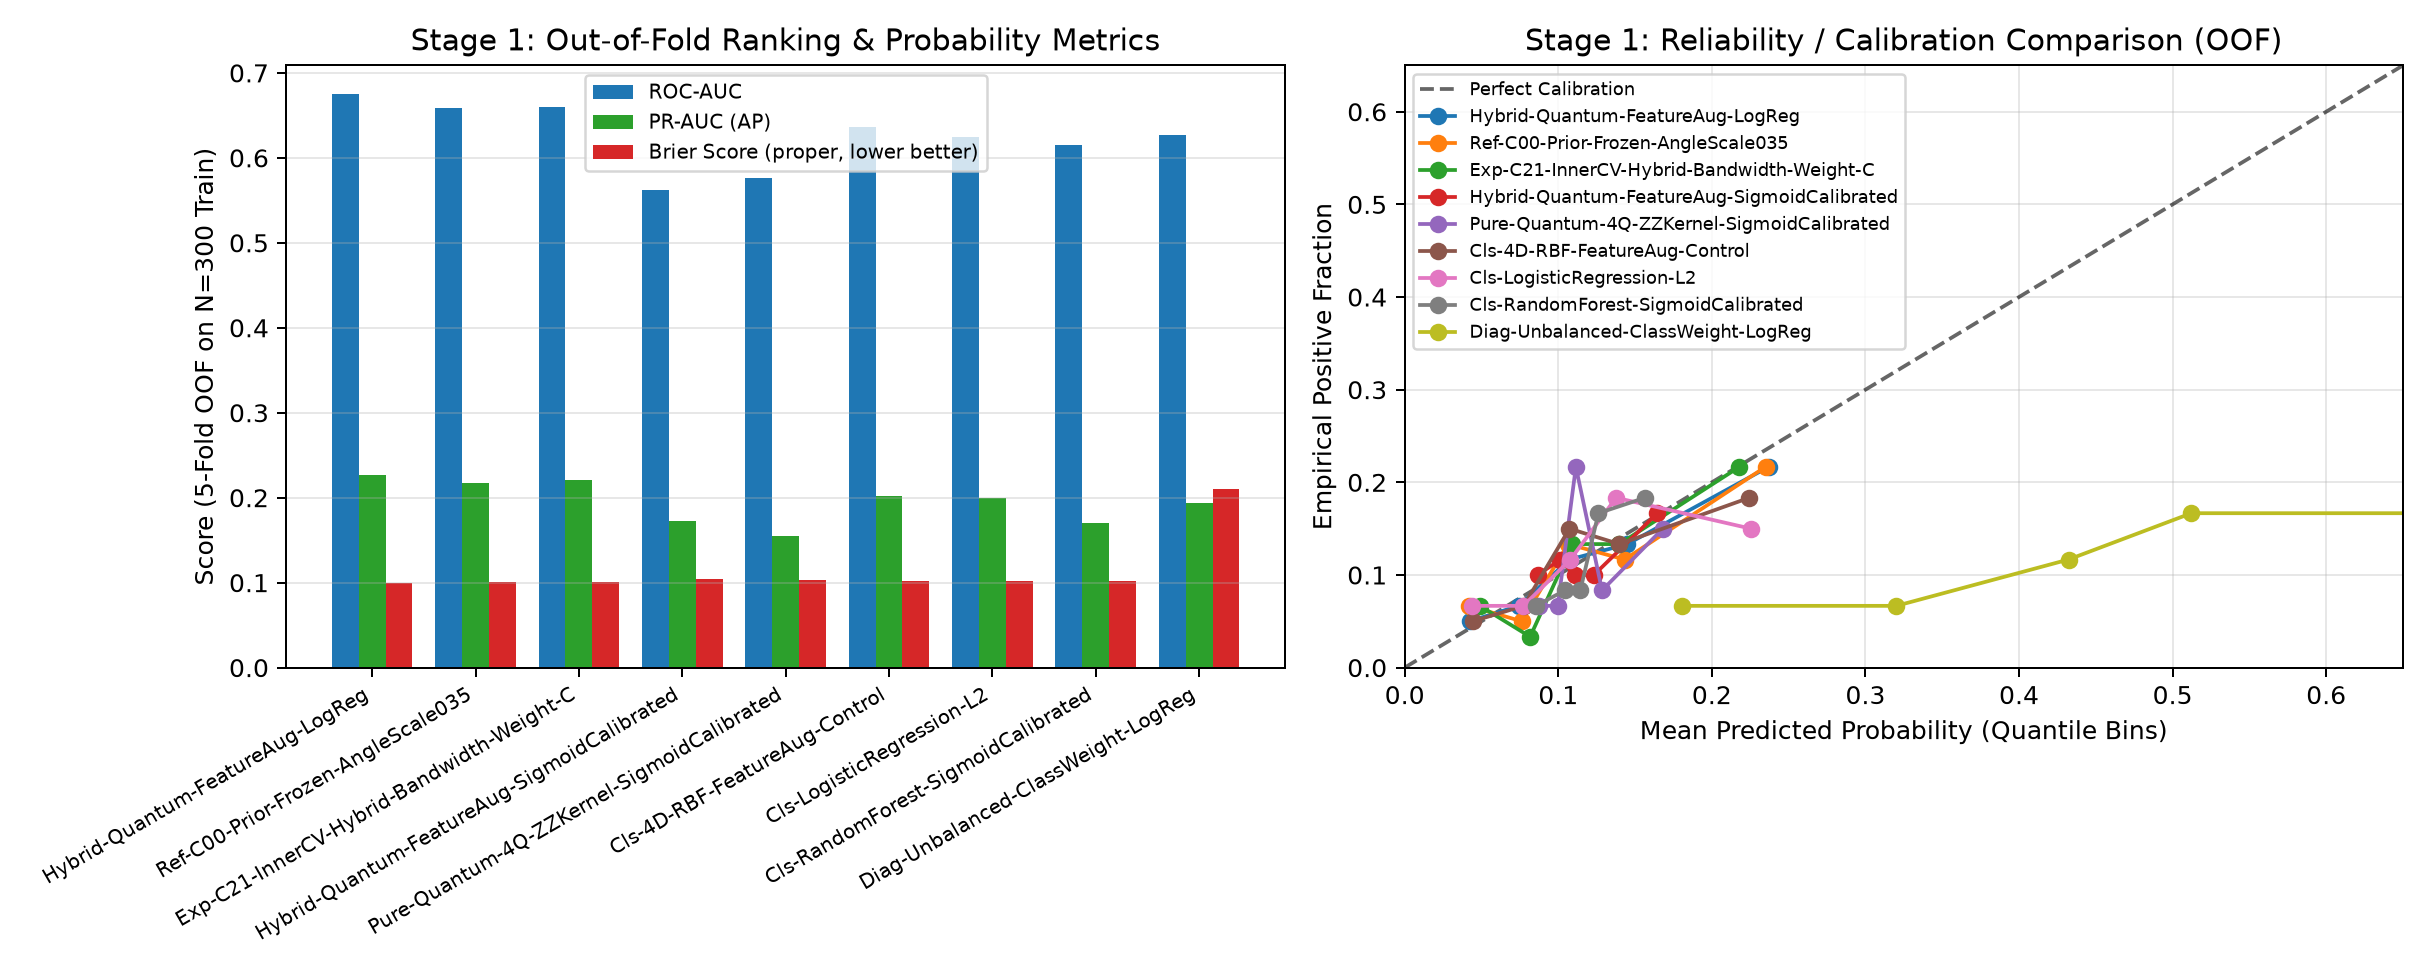

Displaying: stage2_qaoa_and_subset_distribution.png


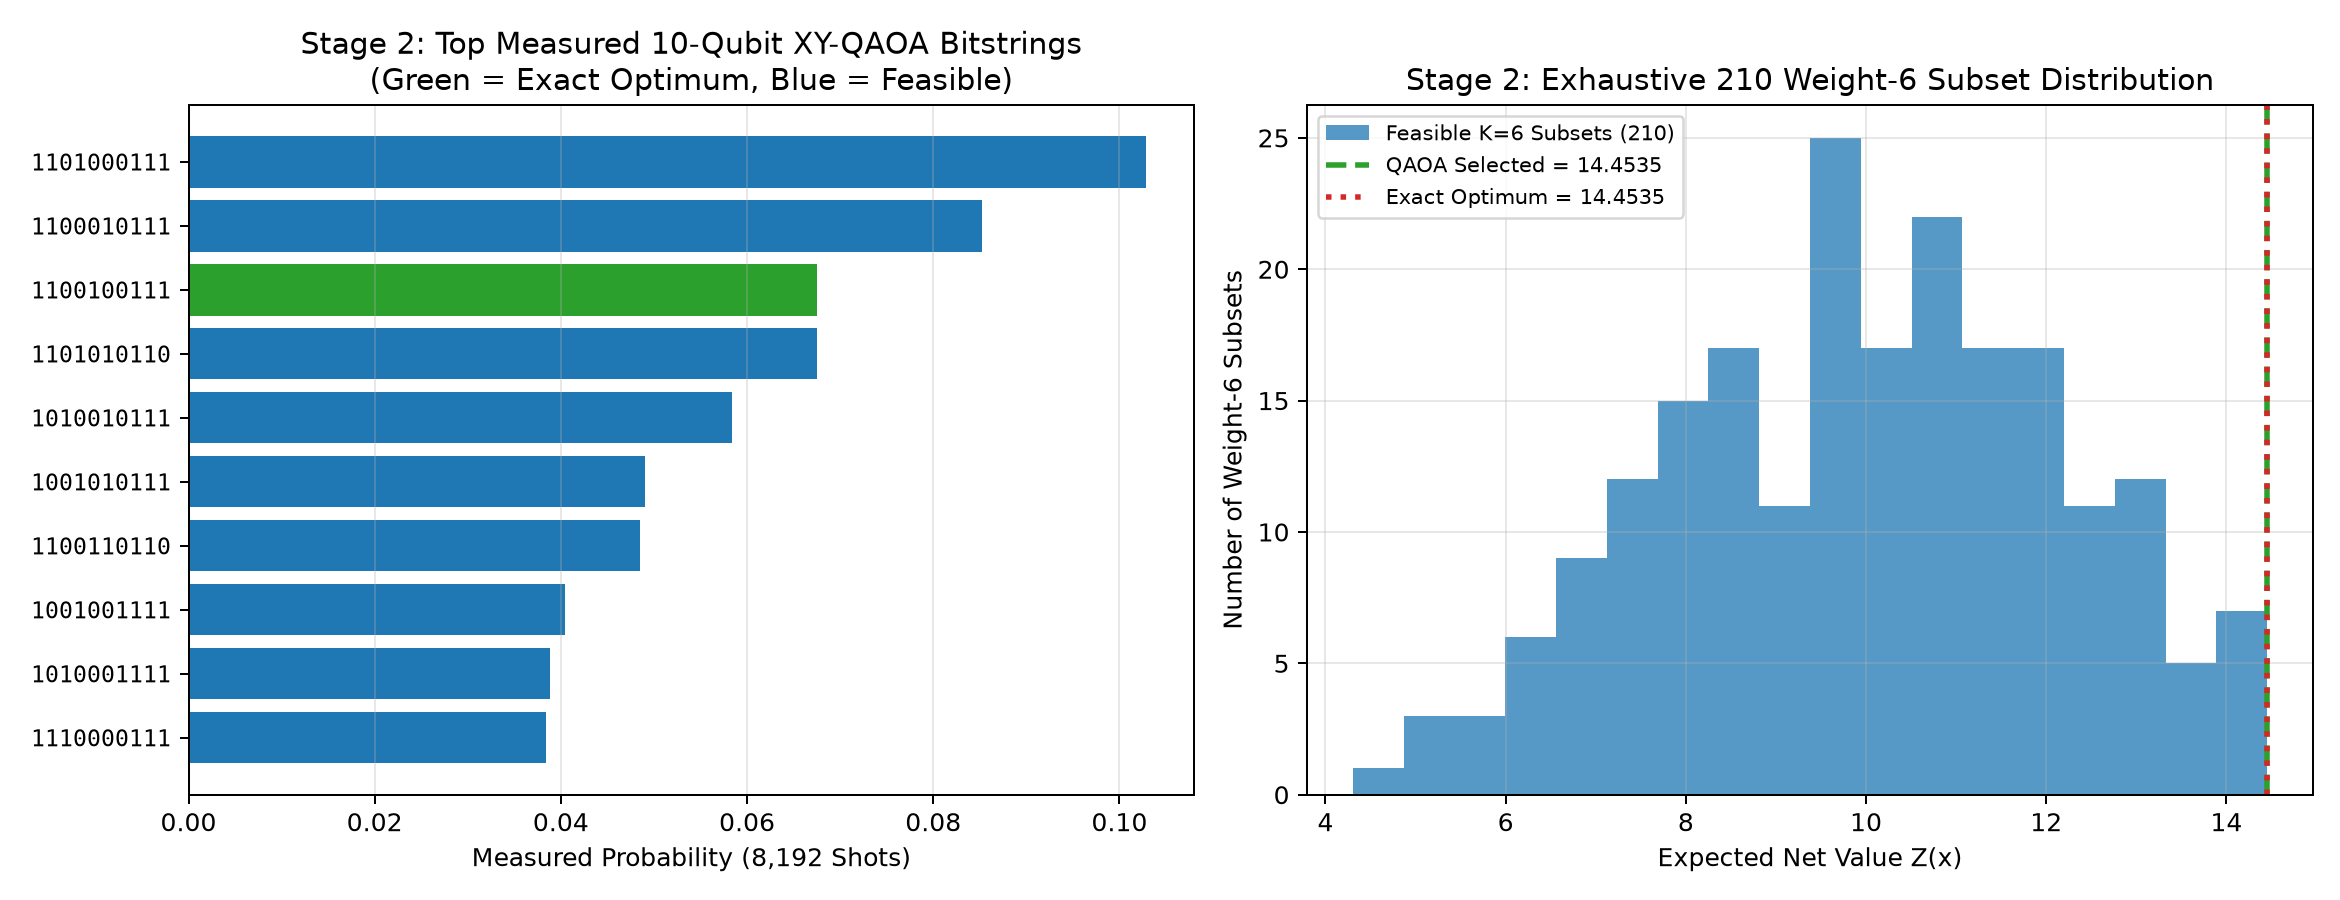

Displaying: stage3_conversion_and_noise_analysis.png


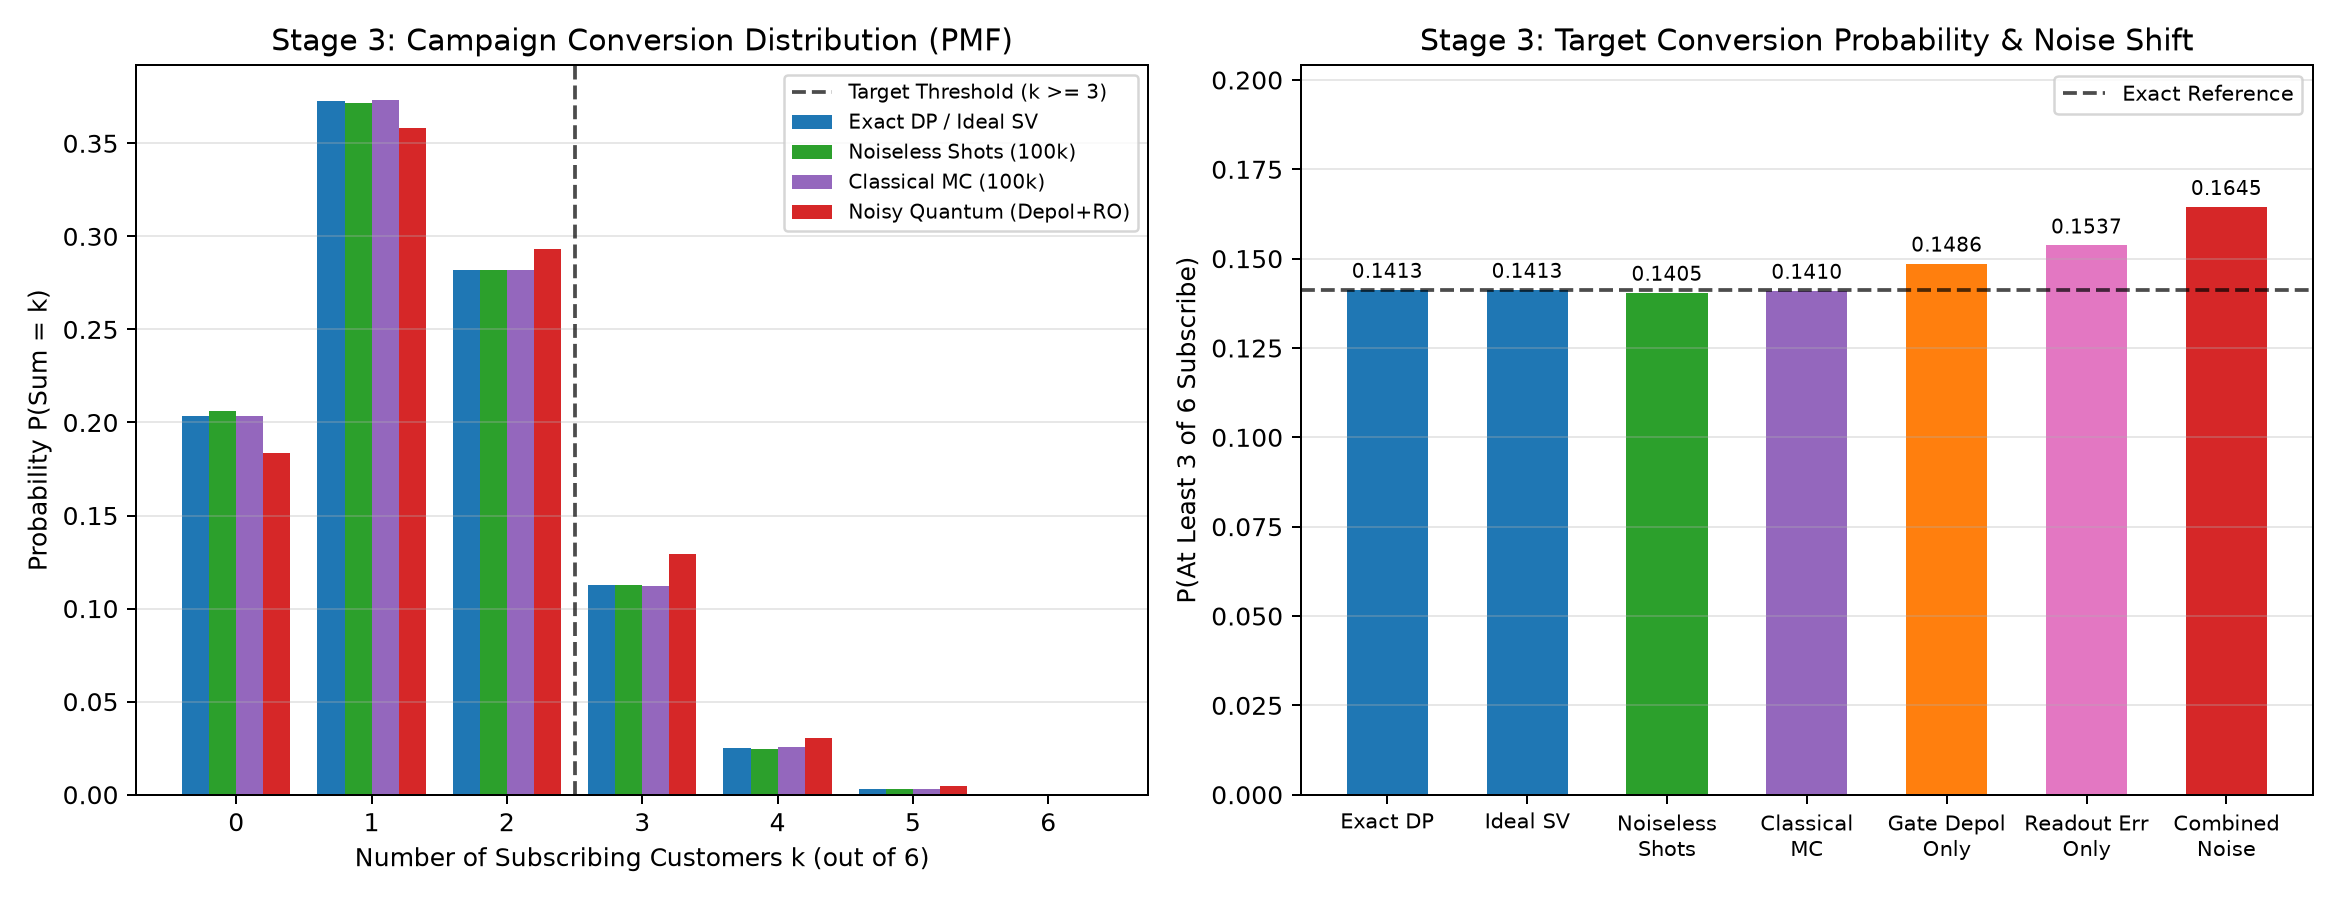

In [5]:
# 5. Publication-Ready Visualizations
from IPython.display import Image, display

fig_dir = PROJECT_ROOT / 'results'
for fig_name in [
    'stage1_validation_and_calibration.png',
    'stage2_qaoa_and_subset_distribution.png',
    'stage3_conversion_and_noise_analysis.png'
]:
    fig_path = fig_dir / fig_name
    if fig_path.exists():
        print(f'Displaying: {fig_name}')
        display(Image(filename=str(fig_path), width=800))
